# Week 5: Supervised Learning — Linear Regression, Logistic Regression, and Decision Trees

Welcome! In the ML Foundations chapter we learned what it means for a model to *learn*: choose a model, measure how wrong it is
with a **loss function**, and adjust its parameters until the loss is small. In this chapter we put those ideas to work on the
three supervised learning models you will reach for most often. **How does each one turn features into a prediction? What does it
learn from the data? How do we read what it learned? And when should we pick one over another?**

---
### What We Will Cover
1. **Supervised Learning Recap** — the two task types and the recipe every model shares
2. **Linear Regression** — predicting a *number* with a straight line (or a flat plane)
3. **Logistic Regression** — predicting a *probability*, then turning it into a category
4. **Decision Trees** — predicting by asking a sequence of yes/no questions
5. **Putting It Together** — comparing the three models head-to-head on the same problems

By the end of this notebook, you will be able to:
* Fit a linear regression, interpret its coefficients, and evaluate it with MAE, RMSE, and $R^2$.
* Explain why linear regression is a poor fit for classification, and how the sigmoid function fixes it.
* Interpret logistic regression coefficients as changes in odds, and choose a classification threshold.
* Explain how a decision tree chooses its splits using Gini impurity, and control overfitting with `max_depth`.
* Compare linear models and trees and choose the right one for a given problem.

**[Date] · [Presenters]**

This notebook follows the lecture. It introduces the ideas; you do not need to master every derivation or code example in one sitting.

> **Note:** All the code cells in this notebook have already been run, so every plot is visible without
> running anything. Re-run them yourself and try changing the numbers — that's the best way to learn!

---

## Setup

Run this cell once to load all the tools we need.

In [1]:
# Run me first!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, log_loss)
import warnings; warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})

print("Ready! You can now run other cells without issues!")

Ready! You can now run other cells without issues!


---
# Part 1: Supervised Learning Recap

## 1.1 Two Kinds of Questions

In **supervised learning** every training example comes with the correct answer (the **label**, `y`). The model studies those
examples and learns to predict the answer for new examples it has never seen. What kind of answer we want decides the task type:

| | **Regression** | **Classification** |
|---|---|---|
| **The target is...** | A **number** | A **category** |
| **Example question** | "What score will this student get on the exam?" | "Will this student pass or fail?" |
| **Example output** | `82.4` | `pass` (often with a probability, like 91%) |
| **Model in this chapter** | Linear Regression, Decision Tree | Logistic Regression, Decision Tree |

> ⚠️ **Watch the name!** Despite its name, **logistic *regression* is a *classification* model.** The name is historical:
> under the hood it fits a regression-style equation, then converts the result into a probability.

---
## 1.2 The Recipe Every Model Shares

Each model in this chapter is defined by the same three choices: *what a prediction looks like*, *what loss it minimizes*,
and *how it searches for the best parameters*.

| | **Linear Regression** | **Logistic Regression** | **Decision Tree** |
|---|---|---|---|
| **Task** | Regression | Classification | Both |
| **A prediction is...** | A weighted sum of the features: $w_1x_1 + \dots + b$ | That weighted sum squeezed into a probability between 0 and 1 | The answer stored in the leaf you reach after a series of yes/no questions |
| **Parameters learned** | Weights $w$ and intercept $b$ | Weights $w$ and intercept $b$ | The questions (which feature, which threshold) and the leaf answers |
| **Loss minimized** | MSE | Log loss | Gini impurity (classification) or MSE (regression), one split at a time |
| **How it's trained** | An exact formula (or gradient descent) | An iterative optimizer, a cousin of gradient descent | Greedy splitting: pick the best question, then repeat on each side |

The good news is that **scikit-learn uses the same three lines for all of them**, so once you can train one, you can train them all:

```python
model = SomeModel(hyperparameters)      # 1. choose a model and its settings
model.fit(X_train, y_train)             # 2. learn the parameters from training data
predictions = model.predict(X_test)     # 3. predict on data the model has never seen
```

Throughout this chapter we'll follow a group of students and try to predict how they do on an exam.

---
# Part 2: Linear Regression 📈

## 2.1 The Main Idea

**Linear regression** predicts a number by drawing the **best straight line** through the data.
With one feature $x$, the model is the equation of a line:

$$\hat{y} = w\,x + b$$

* $w$ is the **slope** (also called the **weight** or **coefficient**): how much $\hat{y}$ changes when $x$ goes up by 1.
* $b$ is the **intercept**: the prediction when $x = 0$.

> **Everyday analogy:** A taxi fare is a flat fee plus a charge per mile: `fare = $2.50 per mile × miles + $3 base`.
> Linear regression looks at a pile of past rides and *figures out* the per-mile rate and the base fee for you.

### Key Vocabulary

| Word | Plain-English Meaning | Example (predicting exam scores) |
|------|----------------------|-----------------------------------|
| **Coefficient / weight** ($w$) | How much the prediction changes per unit of a feature | +4.5 points per hour studied |
| **Intercept** ($b$) | The prediction when every feature is 0 | The score of a student who studies 0 hours |
| **Fitted line** | The line the model learned | `score = 4.5 × hours + 45` |
| **Residual** ($y - \hat{y}$) | How far one prediction is from the true value | Predicted 80, actual 86 → residual = +6 |

Let's fit one.

Learned slope (w):     4.22  -> each extra hour of studying adds about 4.2 points
Learned intercept (b): 46.29 -> predicted score for a student who studies 0 hours

Predicted score for a student who studies 6 hours: 71.6


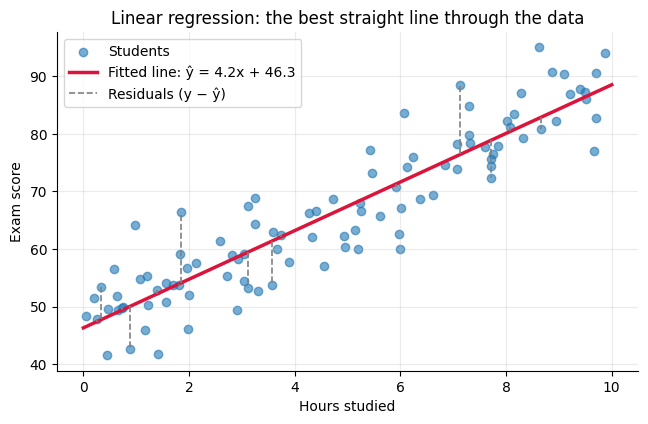

In [2]:
# ── Helper: create exam score data for this section ─────────────────────────
def making_data_for_linear_regression():
    """
    Returns data for 100 students:
      - X: hours studied for the exam (0 to 10), as a 2-D table
      - y: exam score out of 100
    The true relationship is roughly: score = 45 + 4.5 * hours, plus random noise.
    """
    rng = np.random.RandomState(42)
    hours = rng.uniform(0, 10, 100)
    score = 45 + 4.5 * hours + rng.normal(0, 6, 100)
    score = np.clip(score, 0, 100)                 # scores can't go above 100
    return hours.reshape(-1, 1), score             # sklearn wants X as a 2-D table

X_hours, y_score = making_data_for_linear_regression()

lin = LinearRegression()
lin.fit(X_hours, y_score)                          # "fit" = find the best w and b

w, b = lin.coef_[0], lin.intercept_
print(f"Learned slope (w):     {w:.2f}  -> each extra hour of studying adds about {w:.1f} points")
print(f"Learned intercept (b): {b:.2f} -> predicted score for a student who studies 0 hours")
print(f"\nPredicted score for a student who studies 6 hours: {lin.predict([[6]])[0]:.1f}")

# ── Plot the data, the fitted line, and a few residuals ─────────────────────
pred = lin.predict(X_hours)
show = np.arange(0, 100, 7)                        # draw residuals for a handful of students
plt.figure(figsize=(7.5, 4.4))
plt.scatter(X_hours, y_score, alpha=0.6, label='Students')
xs = np.linspace(0, 10, 100).reshape(-1, 1)
plt.plot(xs, lin.predict(xs), color='crimson', lw=2.5, label=f'Fitted line: ŷ = {w:.1f}x + {b:.1f}')
plt.vlines(X_hours[show].ravel(), pred[show], y_score[show], color='gray', ls='--', lw=1.2, label='Residuals (y − ŷ)')
plt.xlabel('Hours studied'); plt.ylabel('Exam score')
plt.title('Linear regression: the best straight line through the data'); plt.legend()
plt.show()

The true pattern we used to generate the data was `score = 45 + 4.5 × hours`. The model never saw that formula, only the
100 noisy examples, and it recovered values close to it. (They aren't exact because of the random noise; more data would get closer.) **That is what "learning the parameters" means.**

---
## 2.2 How Is the "Best" Line Chosen? Least Squares

Each dashed gray line in the plot above is a **residual**: the gap between a student's real score and the line's prediction.
A good line keeps those gaps small. Linear regression picks the $w$ and $b$ that minimize the **mean squared error** (MSE) of the residuals:

$$\text{MSE}(w, b) = \frac{1}{n}\sum_{i=1}^{n}\big(y_i - (w x_i + b)\big)^2$$

This is called **ordinary least squares (OLS)**. Squaring makes every residual positive (so over- and under-predictions don't cancel)
and makes big misses count much more than small ones, as we saw with loss functions.

Let's compare the least-squares line against two worse guesses.

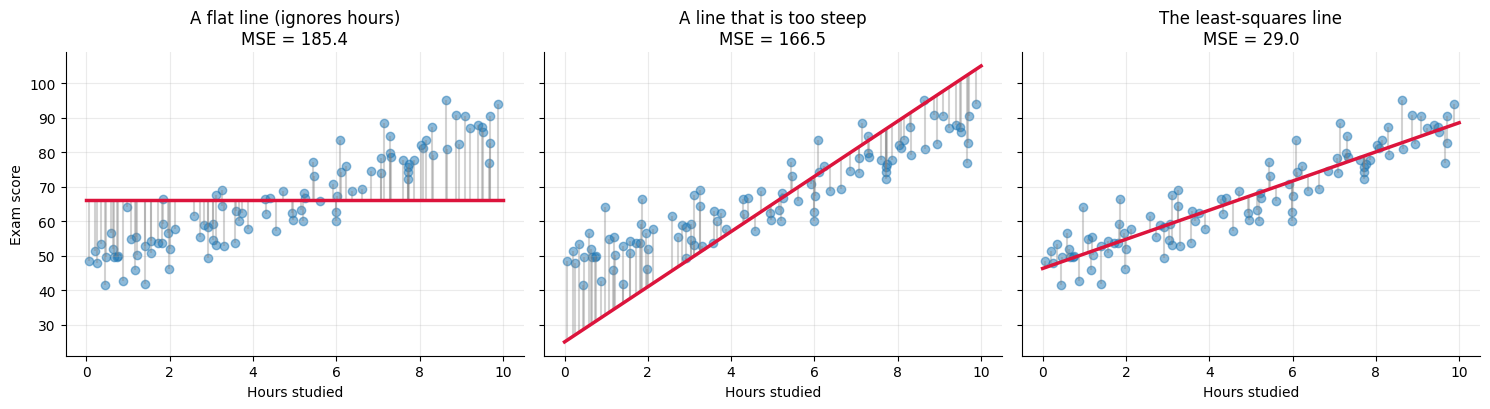

In [3]:
# ── Compare three candidate lines by their MSE ──────────────────────────────
candidates = [(0.0, y_score.mean(), 'A flat line (ignores hours)'),
              (8.0, 25.0,           'A line that is too steep'),
              (w,   b,              'The least-squares line')]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (cw, cb, name) in zip(axes, candidates):
    line_pred = cw * X_hours.ravel() + cb
    mse = np.mean((y_score - line_pred) ** 2)
    ax.scatter(X_hours, y_score, alpha=0.5)
    ax.vlines(X_hours.ravel(), line_pred, y_score, color='gray', alpha=0.35)
    ax.plot(xs, cw * xs + cb, color='crimson', lw=2.5)
    ax.set_title(f'{name}\nMSE = {mse:.1f}'); ax.set_xlabel('Hours studied')
axes[0].set_ylabel('Exam score')
plt.tight_layout(); plt.show()

The least-squares line has the smallest MSE of any possible line. No other choice of $w$ and $b$ can beat it on this training data.

### Finding the minimum: two routes to the same answer

1. **Gradient descent.** Start with a guess and repeatedly step downhill on the loss landscape. This is exactly what we built from scratch in ML Foundations.
2. **An exact formula.** For linear regression with MSE, calculus gives a closed-form answer called the **normal equation**:

$$\boldsymbol{\theta} = (X^\top X)^{-1} X^\top \mathbf{y}$$

Here $X$ is the feature table with an extra column of 1s (for the intercept), and $\boldsymbol{\theta}$ holds $b$ and all the weights.
scikit-learn's `LinearRegression` solves this directly, which is why it doesn't need a learning rate. Let's check that the formula gives the same answer.

In [4]:
# ── Solve the normal equation by hand with numpy ────────────────────────────
X_design = np.column_stack([np.ones(len(X_hours)), X_hours])     # add a column of 1s for the intercept
theta = np.linalg.solve(X_design.T @ X_design, X_design.T @ y_score)

print(f"Normal equation:  b = {theta[0]:.4f},  w = {theta[1]:.4f}")
print(f"scikit-learn:     b = {lin.intercept_:.4f},  w = {lin.coef_[0]:.4f}")
print("Identical! sklearn solves the same equation (using a more numerically careful method).")

Normal equation:  b = 46.2906,  w = 4.2241
scikit-learn:     b = 46.2906,  w = 4.2241
Identical! sklearn solves the same equation (using a more numerically careful method).


> **Why ever use gradient descent then?** The normal equation needs to work with an $(p+1)\times(p+1)$ matrix built from all $p$ features at once.
> With millions of rows or hundreds of thousands of features that gets slow or runs out of memory, and gradient descent scales better.
> Many other models (including logistic regression, next) have **no** exact formula at all, so an iterative optimizer is the only option.

---
## 2.3 Multiple Linear Regression: More Than One Feature

Exam scores depend on more than study time. With $p$ features, the model becomes a weighted sum:

$$\hat{y} = w_1 x_1 + w_2 x_2 + \dots + w_p x_p + b$$

With two features this is a flat **plane** instead of a line; with more it's a "hyperplane" we can't draw, but the math is identical.

**Interpreting a coefficient:** $w_j$ is the change in the prediction when $x_j$ goes up by 1 **while all the other features stay the same**.
That "holding everything else fixed" part matters, as we'll see.

Our new dataset has four features. We secretly built the scores so that coffee has **no real effect**. Let's see whether the model figures that out.

In [5]:
# ── Helper: create a student dataset with several features ──────────────────
def making_data_for_multiple_regression():
    """
    Returns a DataFrame of 300 students with four features and an exam score.
    True relationship (the model doesn't get to see this):
        score = 30 + 4.0*hours_studied + 2.5*hours_slept - 3.0*classes_missed + 0*coffee_cups + noise
    """
    rng = np.random.RandomState(0)
    n = 300
    df = pd.DataFrame({
        'hours_studied':  rng.uniform(0, 10, n),
        'hours_slept':    rng.uniform(4, 9, n),
        'classes_missed': rng.poisson(2, n),
        'coffee_cups':    rng.poisson(2, n),
    })
    df['exam_score'] = (30 + 4.0 * df.hours_studied + 2.5 * df.hours_slept
                        - 3.0 * df.classes_missed + 0.0 * df.coffee_cups + rng.normal(0, 5, n))
    return df

students = making_data_for_multiple_regression()
features = ['hours_studied', 'hours_slept', 'classes_missed', 'coffee_cups']
print(students.head().round(2).to_string(), "\n")

X_multi, y_multi = students[features], students['exam_score']
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_multi, y_multi, test_size=0.25, random_state=42)

multi = LinearRegression().fit(Xm_train, ym_train)

coef_table = pd.DataFrame({'learned coefficient': multi.coef_.round(2),
                           'true value (hidden)': [4.0, 2.5, -3.0, 0.0]}, index=features)
print(coef_table.to_string())
print(f"\nIntercept: {multi.intercept_:.2f}   (true value: 30)")

   hours_studied  hours_slept  classes_missed  coffee_cups  exam_score
0           5.49         8.53               1            1       70.88
1           7.15         7.87               1            2       72.26
2           6.03         5.67               2            6       65.87
3           5.45         4.41               1            1       63.37
4           4.24         6.04               2            4       55.63 

                learned coefficient  true value (hidden)
hours_studied                  4.13                  4.0
hours_slept                    2.35                  2.5
classes_missed                -3.46                 -3.0
coffee_cups                    0.08                  0.0

Intercept: 31.11   (true value: 30)


**Reading the table:**
* `hours_studied ≈ +4`: holding sleep, absences, and coffee fixed, each extra hour of studying adds about 4 points.
* `classes_missed ≈ −3`: each missed class costs about 3 points.
* `coffee_cups ≈ 0`: the model correctly found that coffee doesn't matter (the small leftover value is just noise).

### ⚠️ Raw coefficients are *not* importance scores

It's tempting to say "the biggest coefficient is the most important feature," but each coefficient is measured **in its own feature's units**.
"Points per hour of studying" and "points per missed class" aren't comparable. Measure sleep in *minutes* instead of hours and its coefficient
would shrink 60×, even though sleep matters exactly as much as before.

The fix is to **standardize** the features first (mean 0, standard deviation 1). Then every coefficient means "points per one standard deviation
of this feature," which *is* a fair comparison.

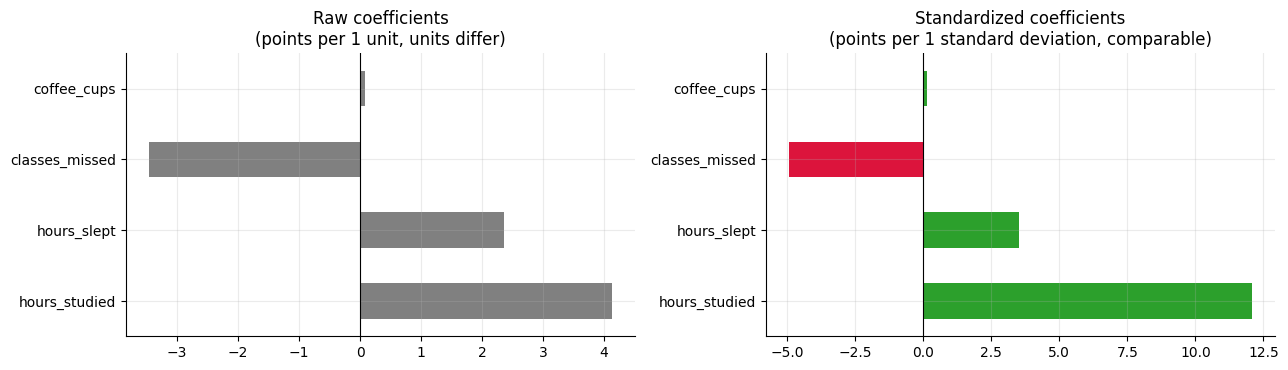

Effect of a one-standard-deviation increase in each feature:
  hours_studied   +12.09 points
  classes_missed   -4.93 points
  hours_slept      +3.50 points
  coffee_cups      +0.12 points


In [6]:
# ── Standardize, then compare coefficients fairly ───────────────────────────
scaled_lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xm_train, ym_train)
std_coefs = pd.Series(scaled_lin[-1].coef_, index=features)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
pd.Series(multi.coef_, index=features).plot.barh(ax=axes[0], color='gray')
axes[0].set_title('Raw coefficients\n(points per 1 unit, units differ)'); axes[0].axvline(0, color='black', lw=0.8)
std_coefs.plot.barh(ax=axes[1], color=['tab:green' if c > 0 else 'crimson' for c in std_coefs])
axes[1].set_title('Standardized coefficients\n(points per 1 standard deviation, comparable)'); axes[1].axvline(0, color='black', lw=0.8)
plt.tight_layout(); plt.show()

print("Effect of a one-standard-deviation increase in each feature:")
for name, c in std_coefs.sort_values(key=abs, ascending=False).items():
    print(f"  {name:<15} {c:+6.2f} points")

After standardizing, `hours_studied` clearly has the largest effect: students' study time varies over a wide range (0 to 10 hours), so it explains the most variation in scores.

> **A warning about cause and effect:** These coefficients describe *associations in the data*, not proof of causation. In our fake data we
> controlled the cause, so we know studying raises scores. In real data, a coefficient can be big because of a hidden factor the model never saw.

---
## 2.4 Evaluating a Regression Model

We always judge a model on **test data it didn't train on**. Three numbers come up constantly:

| Metric | Formula | Plain-English meaning |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y_i-\hat{y}_i\rvert$ | The typical size of a miss, in the target's units |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i-\hat{y}_i)^2}$ | Like MAE, but big misses count extra |
| **$R^2$** | $1 - \dfrac{\sum (y_i-\hat{y}_i)^2}{\sum (y_i-\bar{y})^2}$ | The fraction of the target's variation the model explains |

### Understanding $R^2$

$R^2$ compares your model to the laziest possible model: **always predict the average** $\bar{y}$.

* $R^2 = 1$: perfect predictions.
* $R^2 = 0$: no better than always guessing the average.
* $R^2 < 0$: *worse* than guessing the average (possible on test data!).

> **Everyday analogy:** If the class average on an exam is 70, a "model" that guesses 70 for everyone has $R^2 = 0$. An $R^2$ of 0.8 means
> your model removed 80% of the squared error that guessing-the-average would make.

Next to the numbers, it's also worth plotting the **residuals**. If the model is a good fit, they should look like random noise centered on zero, with no pattern.

Train  MAE =  4.00   RMSE =  4.99   R² = 0.887
Test   MAE =  4.11   RMSE =  5.26   R² = 0.825

Train and test errors are close: no sign of overfitting.
The test RMSE is close to the noise level (5 points) we built into the data, so there's little left to learn.


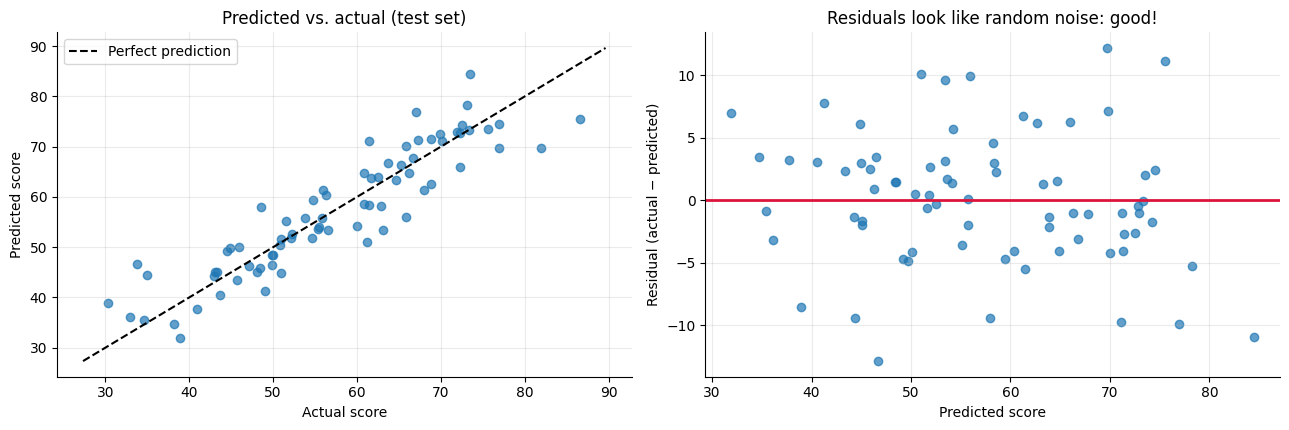

In [7]:
# ── Evaluate on training and test data ─────────────────────────────────────
def regression_report(model, X, y, label):
    p = model.predict(X)
    print(f"{label:<6} MAE = {mean_absolute_error(y, p):5.2f}   "
          f"RMSE = {np.sqrt(mean_squared_error(y, p)):5.2f}   R² = {r2_score(y, p):.3f}")
    return p

_ = regression_report(multi, Xm_train, ym_train, 'Train')
test_pred = regression_report(multi, Xm_test, ym_test, 'Test')
print("\nTrain and test errors are close: no sign of overfitting.")
print("The test RMSE is close to the noise level (5 points) we built into the data, so there's little left to learn.")

# ── Plots: predicted vs. actual, and residuals ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].scatter(ym_test, test_pred, alpha=0.7)
lims = [ym_test.min() - 3, ym_test.max() + 3]
axes[0].plot(lims, lims, 'k--', lw=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual score'); axes[0].set_ylabel('Predicted score')
axes[0].set_title('Predicted vs. actual (test set)'); axes[0].legend()

axes[1].scatter(test_pred, ym_test - test_pred, alpha=0.7)
axes[1].axhline(0, color='crimson', lw=2)
axes[1].set_xlabel('Predicted score'); axes[1].set_ylabel('Residual (actual − predicted)')
axes[1].set_title('Residuals look like random noise: good!')
plt.tight_layout(); plt.show()

---
## 2.5 When a Straight Line Isn't Enough

Linear regression assumes the relationship really *is* (roughly) a straight line. What if it isn't? Suppose scores depend on sleep in a curved way:
too little sleep hurts, and so does oversleeping, with the best results around 8 hours.

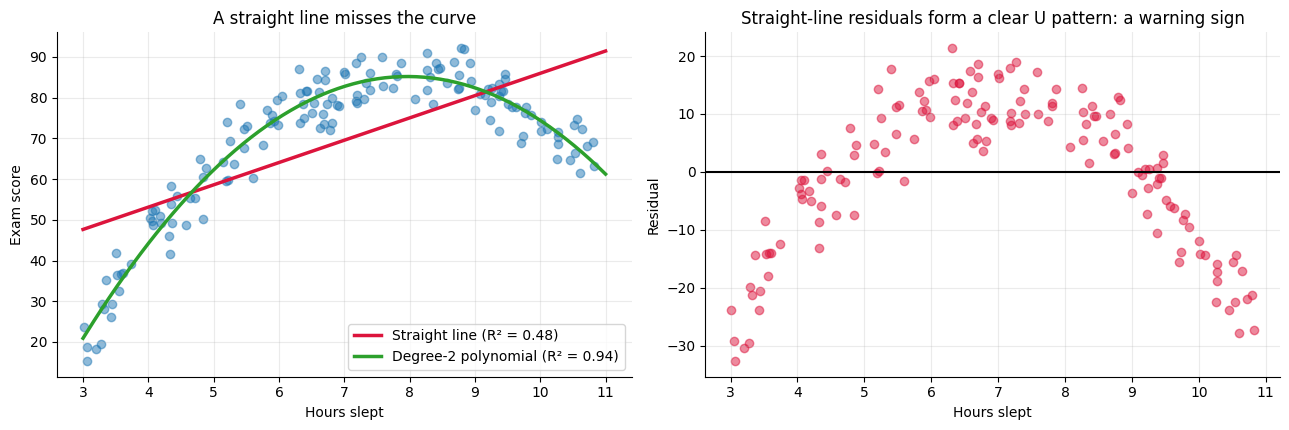

In [8]:
# ── Helper: create curved data ──────────────────────────────────────────────
def making_data_for_curved_relationship():
    """
    Returns 150 students: hours slept the night before (3 to 11) and exam score.
    True relationship: an upside-down U that peaks at 8 hours of sleep.
        score = 85 - 2.5 * (sleep - 8)^2 + noise
    """
    rng = np.random.RandomState(7)
    sleep = rng.uniform(3, 11, 150)
    score = 85 - 2.5 * (sleep - 8) ** 2 + rng.normal(0, 5, 150)
    return sleep.reshape(-1, 1), score

X_sleep, y_sleep = making_data_for_curved_relationship()

straight = LinearRegression().fit(X_sleep, y_sleep)
curved   = make_pipeline(PolynomialFeatures(degree=2), LinearRegression()).fit(X_sleep, y_sleep)

grid = np.linspace(3, 11, 200).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].scatter(X_sleep, y_sleep, alpha=0.5)
axes[0].plot(grid, straight.predict(grid), color='crimson', lw=2.5, label=f'Straight line (R² = {r2_score(y_sleep, straight.predict(X_sleep)):.2f})')
axes[0].plot(grid, curved.predict(grid),  color='tab:green', lw=2.5, label=f'Degree-2 polynomial (R² = {r2_score(y_sleep, curved.predict(X_sleep)):.2f})')
axes[0].set_xlabel('Hours slept'); axes[0].set_ylabel('Exam score'); axes[0].set_title('A straight line misses the curve'); axes[0].legend()

resid = y_sleep - straight.predict(X_sleep)
axes[1].scatter(X_sleep, resid, alpha=0.5, color='crimson')
axes[1].axhline(0, color='black', lw=1.5)
axes[1].set_xlabel('Hours slept'); axes[1].set_ylabel('Residual')
axes[1].set_title('Straight-line residuals form a clear U pattern: a warning sign')
plt.tight_layout(); plt.show()

The residual plot on the right is the giveaway: the errors aren't random, they form a **pattern**. A pattern in the residuals means there is
structure the model failed to capture.

The fix was to add a squared feature, $x^2$, using `PolynomialFeatures(degree=2)`. The model becomes $\hat{y} = w_1 x + w_2 x^2 + b$.

> **Wait, is that still "linear" regression?** Yes! "Linear" means the prediction is a weighted sum of the features, i.e. linear in the
> **parameters** $w$. The features themselves can be anything we compute, including $x^2$. Just remember the bias–variance lesson:
> a high polynomial degree can overfit.

---
### Pros & Cons — Linear Regression

| Strengths | Weaknesses |
|-----------|------------|
| Very fast to train, even on large data | Assumes a straight-line relationship unless you engineer features |
| Coefficients are easy to explain ("+4 points per hour") | Sensitive to outliers, because squared errors amplify big misses |
| Works well with limited data | Coefficients become unstable when features are strongly correlated with each other |
| A great baseline to beat | Can't capture interactions (e.g. "studying helps *more* if you also slept") unless you add them as features |

**Best used when:** the target is a number, the relationship is roughly linear, and you want a model you can explain.

### Key Parameters — Linear Regression

`LinearRegression` itself has almost nothing to tune. Most of the decisions are about **what features you give it**.

| Parameter / choice | What it does | Effect of changing it |
|-----------|-------------|----------------------|
| `fit_intercept` | Whether to learn the intercept $b$ (default `True`) | Leave it on unless you have a strong reason to force the line through 0 |
| `PolynomialFeatures(degree=...)` | Adds $x^2, x^3, \dots$ (and products of features) | Higher degree = more flexible curve, more risk of overfitting |
| `StandardScaler()` | Puts features on the same scale | Doesn't change predictions for plain `LinearRegression`, but makes coefficients comparable (and is required for Ridge/Lasso) |
| `Ridge(alpha=...)`, `Lasso(alpha=...)` | Regularized versions that penalize large coefficients | Larger `alpha` = simpler model, less variance (covered in the regularization chapter) |

### ✏️ Quick Check

1. A model predicting apartment rent has coefficient `+1.8` on `square_feet`. What does that mean in plain English?
2. Model A has test $R^2 = 0.85$; Model B has test $R^2 = -0.10$. What does B's negative value tell you?
3. You plot residuals vs. predictions and see a clear curve. What should you try?

<details>
<summary><b>Click for answers</b></summary>

1. Holding every other feature fixed, each extra square foot is associated with about **$1.80 more rent** per month.
2. Model B is **worse than just predicting the average rent** for every apartment. Something is badly wrong (overfitting, a bug, or the wrong features).
3. The relationship isn't linear. Try **adding features** like polynomial terms or transformations (e.g. `log`), or use a more flexible model like a decision tree.
</details>

---
# Part 3: Logistic Regression 🔀

## 3.1 The Problem: Predicting a Category

Now the question changes from *"what score will this student get?"* to *"will this student **pass** (1) or **fail** (0)?"*
The target has only two possible values. Why not just run linear regression on the 0s and 1s and call anything above 0.5 a "pass"?
Let's try it.

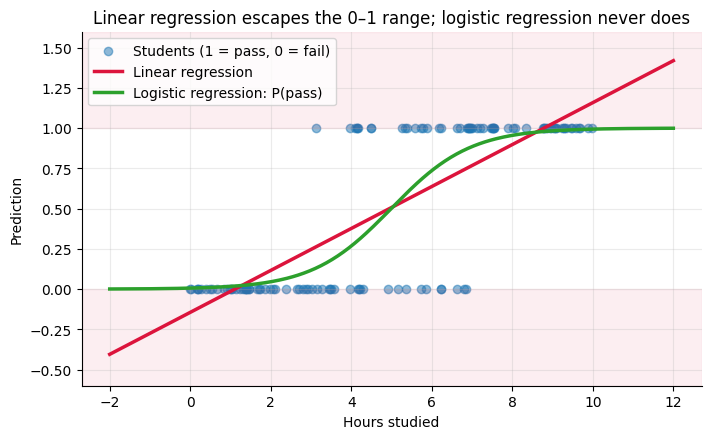

 0 hours studied -> linear regression says -0.14,  logistic regression says P(pass) = 0.006
12 hours studied -> linear regression says +1.42,  logistic regression says P(pass) = 0.999


In [9]:
# ── Helper: create pass/fail data ───────────────────────────────────────────
def making_data_for_logistic_regression():
    """
    Returns 120 students:
      - X: hours studied (0 to 10), as a 2-D table
      - y: 1 if the student passed, 0 if they failed
    The chance of passing rises smoothly with study time, crossing 50% at about 5 hours.
    """
    rng = np.random.RandomState(1)
    hours = rng.uniform(0, 10, 120)
    p_pass = 1 / (1 + np.exp(-1.3 * (hours - 5)))
    passed = (rng.rand(120) < p_pass).astype(int)
    return hours.reshape(-1, 1), passed

X_pass, y_pass = making_data_for_logistic_regression()

line_model = LinearRegression().fit(X_pass, y_pass)          # the WRONG tool, for comparison
logit      = LogisticRegression().fit(X_pass, y_pass)        # the right tool

grid = np.linspace(-2, 12, 300).reshape(-1, 1)
plt.figure(figsize=(8, 4.6))
plt.scatter(X_pass, y_pass, alpha=0.5, label='Students (1 = pass, 0 = fail)')
plt.plot(grid, line_model.predict(grid), color='crimson', lw=2.5, label='Linear regression')
plt.plot(grid, logit.predict_proba(grid)[:, 1], color='tab:green', lw=2.5, label='Logistic regression: P(pass)')
plt.axhspan(1, 1.6, color='crimson', alpha=0.07); plt.axhspan(-0.6, 0, color='crimson', alpha=0.07)
plt.ylim(-0.6, 1.6); plt.xlabel('Hours studied'); plt.ylabel('Prediction')
plt.title('Linear regression escapes the 0–1 range; logistic regression never does'); plt.legend(loc='upper left')
plt.show()

for h in [0, 12]:
    print(f"{h:>2} hours studied -> linear regression says {line_model.predict([[h]])[0]:+.2f},  "
          f"logistic regression says P(pass) = {logit.predict_proba([[h]])[0, 1]:.3f}")

Linear regression's predictions go **below 0 and above 1** (the shaded regions). Those can't be probabilities: what would a
"−18% chance of passing" mean? A straight line is also easily dragged around by points far from the boundary.

What we want is an S-shaped curve that stays between 0 and 1. That's exactly what logistic regression draws.

---
## 3.2 The Sigmoid Function

Logistic regression starts with the same weighted sum as linear regression, then passes it through the **sigmoid** (or **logistic**) function:

$$z = w\,x + b \qquad\longrightarrow\qquad \hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

The sigmoid takes *any* number and squashes it into the range 0 to 1:

| $z$ (the weighted sum) | $\sigma(z)$ (the probability) | Meaning |
|:---:|:---:|---|
| −5 | 0.007 | Almost certainly class 0 |
| −1 | 0.27 | Leaning class 0 |
| 0 | **0.50** | A coin flip: this is the decision boundary |
| +1 | 0.73 | Leaning class 1 |
| +5 | 0.993 | Almost certainly class 1 |

To turn the probability into a category, apply a **threshold** (0.5 by default): predict 1 if $\hat{p} \ge 0.5$, otherwise 0.

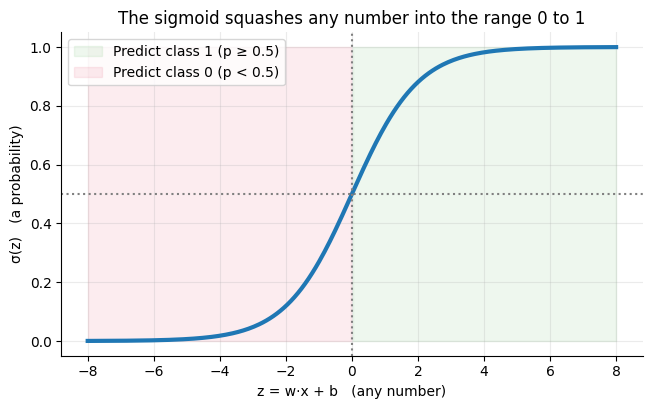

sigmoid(-5) = 0.007
sigmoid(-1) = 0.269
sigmoid(+0) = 0.500
sigmoid(+1) = 0.731
sigmoid(+5) = 0.993


In [10]:
# ── Plot the sigmoid function ───────────────────────────────────────────────
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 300)
plt.figure(figsize=(7.5, 4.2))
plt.plot(z, sigmoid(z), lw=3)
plt.axhline(0.5, color='gray', ls=':'); plt.axvline(0, color='gray', ls=':')
plt.fill_between(z, 0, 1, where=z >= 0, color='tab:green', alpha=0.08, label='Predict class 1 (p ≥ 0.5)')
plt.fill_between(z, 0, 1, where=z < 0,  color='crimson',   alpha=0.08, label='Predict class 0 (p < 0.5)')
plt.xlabel('z = w·x + b   (any number)'); plt.ylabel('σ(z)   (a probability)')
plt.title('The sigmoid squashes any number into the range 0 to 1'); plt.legend(loc='upper left')
plt.show()

for val in [-5, -1, 0, 1, 5]:
    print(f"sigmoid({val:+d}) = {sigmoid(val):.3f}")

---
## 3.3 Reading the Coefficients: Odds

Logistic regression's coefficients are a little less direct than linear regression's, because the sigmoid bends everything.
The cleanest way to read them uses **odds**:

$$\text{odds} = \frac{p}{1 - p} \qquad\qquad \text{(a 75% chance means odds of } 0.75/0.25 = 3\text{, or "3 to 1")}$$

With a bit of algebra, the logistic model says the **log of the odds** is linear in the features:

$$\ln\!\left(\frac{p}{1-p}\right) = w\,x + b$$

So each extra unit of $x$ adds $w$ to the log-odds, which means it **multiplies the odds by $e^{w}$**. That number $e^{w}$ is called the **odds ratio**.

In [11]:
# ── Interpret the fitted pass/fail model ────────────────────────────────────
w_log, b_log = logit.coef_[0, 0], logit.intercept_[0]
print(f"Weight w:     {w_log:.3f}")
print(f"Intercept b:  {b_log:.3f}")
print(f"Odds ratio:   e^w = {np.exp(w_log):.2f}  -> each extra hour multiplies the odds of passing by {np.exp(w_log):.2f}")
print(f"50/50 point:  z = 0 when hours = -b/w = {-b_log / w_log:.2f}   (we built the data to cross 50% at 5 hours)\n")

hours_to_check = np.array([[2], [4], [5], [6], [8]])
probs = logit.predict_proba(hours_to_check)[:, 1]
table = pd.DataFrame({'hours studied': hours_to_check.ravel(),
                      'z = w·x + b':   (w_log * hours_to_check.ravel() + b_log).round(2),
                      'P(pass)':       probs.round(3),
                      'odds':          (probs / (1 - probs)).round(2),
                      'prediction':    np.where(probs >= 0.5, 'pass', 'fail')})
print(table.to_string(index=False))

Weight w:     1.016
Intercept b:  -5.071
Odds ratio:   e^w = 2.76  -> each extra hour multiplies the odds of passing by 2.76
50/50 point:  z = 0 when hours = -b/w = 4.99   (we built the data to cross 50% at 5 hours)

 hours studied  z = w·x + b  P(pass)  odds prediction
             2        -3.04    0.046  0.05       fail
             4        -1.01    0.268  0.37       fail
             5         0.01    0.502  1.01       pass
             6         1.03    0.736  2.79       pass
             8         3.06    0.955 21.30       pass


Look at the `odds` column for 2 → 4 → 6 → 8 hours: every two-hour step multiplies the odds by the same factor, $e^{2w}$ (about 7.5 here).
That constant multiplication is what the odds ratio describes. Notice the *probability* does **not** rise by the same amount each hour:
it changes fastest near 50% and flattens out near 0% and 100%.

---
## 3.4 How Logistic Regression Is Trained

Logistic regression minimizes **log loss** (binary cross-entropy), which we met in ML Foundations:

$$\text{Log Loss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[\, y_i \ln(\hat{p}_i) + (1-y_i)\ln(1-\hat{p}_i) \,\Big]$$

It punishes confident wrong answers severely and rewards well-calibrated probabilities. Unlike linear regression there's **no exact formula**
for the best weights, so the model is trained iteratively. A remarkable fact makes this easy: the gradient of log loss has *the same form*
as the linear regression gradient, just with probabilities in place of raw predictions:

$$\frac{\partial L}{\partial w} = \frac{1}{n}\sum_{i=1}^{n} x_i\,(\hat{p}_i - y_i) \qquad\qquad \frac{\partial L}{\partial b} = \frac{1}{n}\sum_{i=1}^{n} (\hat{p}_i - y_i)$$

Let's train logistic regression with the same gradient-descent loop as before and compare it to scikit-learn.

Gradient descent:  w = 3.1614,  b = 0.0185,  log loss = 0.2848
scikit-learn:      w = 3.1624,  b = 0.0185


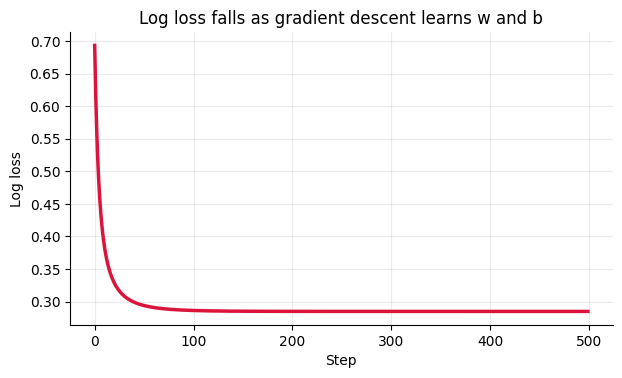

In [12]:
# ── Logistic regression from scratch with gradient descent ──────────────────
x_std = (X_pass.ravel() - X_pass.mean()) / X_pass.std()     # standardize, as before

w_gd, b_gd, lr = 0.0, 0.0, 0.5
loss_history = []
for step in range(500):
    p_hat = sigmoid(w_gd * x_std + b_gd)                    # 1. predict probabilities
    loss_history.append(log_loss(y_pass, p_hat))            # 2. measure the loss
    w_gd -= lr * np.mean(x_std * (p_hat - y_pass))          # 3. step downhill
    b_gd -= lr * np.mean(p_hat - y_pass)

# sklearn on the same standardized feature, with its default regularization turned off for a fair comparison
sk_logit = LogisticRegression(penalty=None).fit(x_std.reshape(-1, 1), y_pass)
print(f"Gradient descent:  w = {w_gd:.4f},  b = {b_gd:.4f},  log loss = {loss_history[-1]:.4f}")
print(f"scikit-learn:      w = {sk_logit.coef_[0, 0]:.4f},  b = {sk_logit.intercept_[0]:.4f}")

plt.figure(figsize=(7, 3.8))
plt.plot(loss_history, lw=2.5, color='crimson')
plt.xlabel('Step'); plt.ylabel('Log loss'); plt.title('Log loss falls as gradient descent learns w and b')
plt.show()

They match. scikit-learn uses a faster optimizer (called `lbfgs`) than our plain loop, but the idea is identical:
**compute the gradient of the loss, step the opposite way, repeat.**

> ⚠️ **sklearn gotcha:** `LogisticRegression()` applies **L2 regularization by default** (`C=1.0`), which gently shrinks the weights toward 0.
> That's usually helpful, but it means the default coefficients are a bit smaller than the unregularized ones. We passed `penalty=None` above
> to compare apples to apples. Because of the penalty, it's good practice to **standardize** features before logistic regression.

---
## 3.5 The Decision Boundary

With two features, the model computes $z = w_1x_1 + w_2x_2 + b$ and predicts class 1 wherever $z \ge 0$. The set of points where $z = 0$
exactly is a **straight line**, called the **decision boundary**. Everything on one side is predicted "pass," everything on the other "fail."
Logistic regression is a **linear classifier**: its boundary is always a line (or a flat plane, with more features).

Learned model:  z = 1.36·hours + 0.42·problems + (-13.35)
Test accuracy:  91.1%


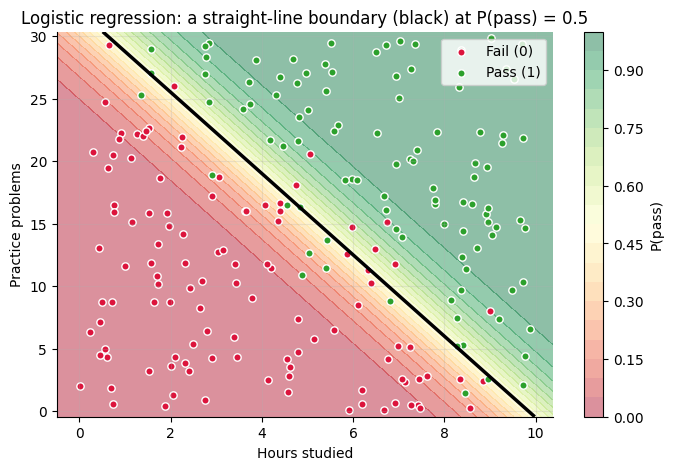

In [13]:
# ── Helper: create pass/fail data with two features ─────────────────────────
def making_data_for_2d_logistic():
    """
    Returns 300 students with two features and a pass (1) / fail (0) label:
      - hours studied (0 to 10)
      - practice problems completed (0 to 30)
    Both features raise the chance of passing.
    """
    rng = np.random.RandomState(3)
    n = 300
    hours    = rng.uniform(0, 10, n)
    problems = rng.uniform(0, 30, n)
    z = 0.9 * (hours - 5) + 0.3 * (problems - 15)
    passed = (rng.rand(n) < sigmoid(z)).astype(int)
    return np.column_stack([hours, problems]), passed

def plot_decision_boundary(ax, model, X, y, title, xlabel='Hours studied', ylabel='Practice problems', proba=False):
    """Color the background by the model's prediction, then draw the data on top."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    grid_pts = np.c_[xx.ravel(), yy.ravel()]
    if proba:
        Z = model.predict_proba(grid_pts)[:, 1].reshape(xx.shape)
        cf = ax.contourf(xx, yy, Z, levels=20, cmap='RdYlGn', alpha=0.45)
        ax.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2.5)
        plt.colorbar(cf, ax=ax, label='P(pass)')
    else:
        Z = model.predict(grid_pts).reshape(xx.shape)
        ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=['crimson', 'tab:green'], alpha=0.18)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c='crimson',   edgecolor='white', s=28, label='Fail (0)')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:green', edgecolor='white', s=28, label='Pass (1)')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)

X2, y2 = making_data_for_2d_logistic()
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, random_state=42, stratify=y2)

logit2 = LogisticRegression().fit(X2_train, y2_train)
(w1, w2), b2 = logit2.coef_[0], logit2.intercept_[0]
print(f"Learned model:  z = {w1:.2f}·hours + {w2:.2f}·problems + ({b2:.2f})")
print(f"Test accuracy:  {logit2.score(X2_test, y2_test):.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
plot_decision_boundary(ax, logit2, X2_train, y2_train, 'Logistic regression: a straight-line boundary (black) at P(pass) = 0.5', proba=True)
ax.legend(loc='upper right')
plt.show()

The background shading shows the predicted probability, and the black line is where it equals exactly 0.5. Students far from the line get
confident predictions; students near the line are close to a coin flip, and that's where the model's mistakes happen.

---
## 3.6 Choosing a Threshold, and Evaluating a Classifier

A threshold of 0.5 is just a default. You can move it, and you should when the two kinds of mistakes have different costs.
Recall the **confusion matrix** and the metrics built from it:

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | $\frac{TP + TN}{\text{all}}$ | What fraction of all predictions were right? |
| **Precision** | $\frac{TP}{TP + FP}$ | When the model says "1", how often is it right? |
| **Recall** | $\frac{TP}{TP + FN}$ | Of all the real 1s, how many did the model catch? |

* **Lower the threshold** → the model says "1" more easily → it catches more real 1s (**recall ↑**) but raises more false alarms (**precision ↓**).
* **Raise the threshold** → the model says "1" only when very sure → **precision ↑**, **recall ↓**.

> **Everyday analogy:** A smoke detector with a low threshold catches every fire but also goes off when you make toast.
> A high threshold rarely gives false alarms but might sleep through a small fire. For smoke detectors, we choose a low threshold on purpose.

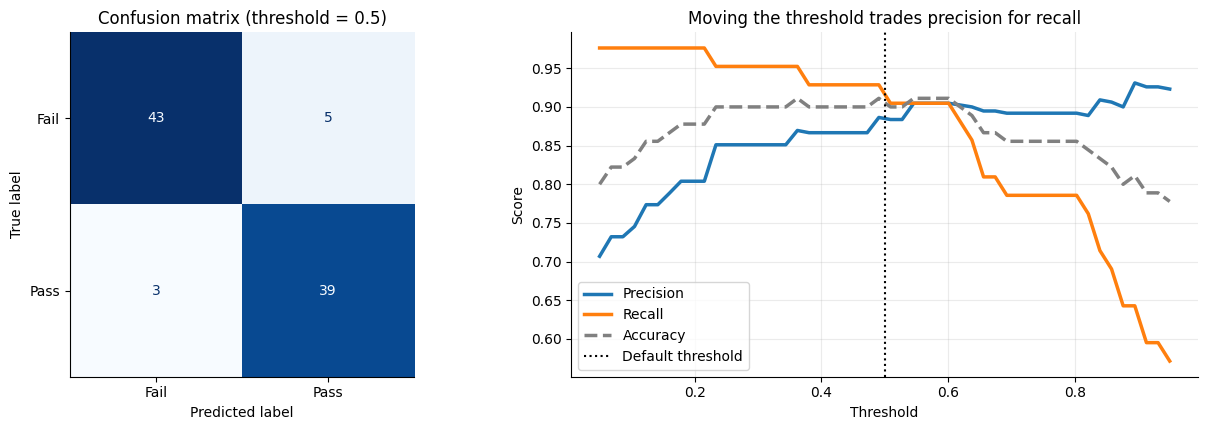

Threshold  Precision   Recall  Accuracy
----------------------------------------
      0.2      80.4%    97.6%     87.8%
      0.5      88.6%    92.9%     91.1%
      0.8      89.2%    78.6%     85.6%


In [14]:
# ── Confusion matrix at the default 0.5 threshold ───────────────────────────
p_test = logit2.predict_proba(X2_test)[:, 1]          # probability of class 1 (pass)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ConfusionMatrixDisplay(confusion_matrix(y2_test, (p_test >= 0.5).astype(int)),
                       display_labels=['Fail', 'Pass']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion matrix (threshold = 0.5)'); axes[0].grid(False)

# ── Sweep the threshold and watch precision and recall trade off ────────────
thresholds = np.linspace(0.05, 0.95, 50)
prec = [precision_score(y2_test, (p_test >= t).astype(int), zero_division=1) for t in thresholds]
rec  = [recall_score(y2_test,    (p_test >= t).astype(int)) for t in thresholds]
acc  = [accuracy_score(y2_test,  (p_test >= t).astype(int)) for t in thresholds]
axes[1].plot(thresholds, prec, lw=2.5, label='Precision')
axes[1].plot(thresholds, rec,  lw=2.5, label='Recall')
axes[1].plot(thresholds, acc,  lw=2.5, ls='--', color='gray', label='Accuracy')
axes[1].axvline(0.5, color='black', ls=':', label='Default threshold')
axes[1].set_xlabel('Threshold'); axes[1].set_ylabel('Score'); axes[1].set_title('Moving the threshold trades precision for recall')
axes[1].legend()
plt.tight_layout(); plt.show()

print(f"{'Threshold':>9} {'Precision':>10} {'Recall':>8} {'Accuracy':>9}")
print("-" * 40)
for t in [0.2, 0.5, 0.8]:
    pred_t = (p_test >= t).astype(int)
    print(f"{t:>9} {precision_score(y2_test, pred_t):>10.1%} {recall_score(y2_test, pred_t):>8.1%} {accuracy_score(y2_test, pred_t):>9.1%}")

### More than two classes?

Logistic regression extends naturally to 3+ classes (e.g. grade A / B / C). Instead of one sigmoid, it learns one weighted sum **per class**
and converts them into probabilities that add up to 1 using the **softmax** function. In scikit-learn you don't have to change anything:
`LogisticRegression().fit(X, y)` detects multiple classes automatically.

---
### Pros & Cons — Logistic Regression

| Strengths | Weaknesses |
|-----------|------------|
| Outputs real probabilities, not just labels | The decision boundary is a straight line unless you engineer features |
| Fast to train and to predict | Can't capture interactions or curved boundaries on its own |
| Coefficients are interpretable (odds ratios) | Needs feature scaling to behave well with regularization |
| A strong, standard baseline for classification | Struggles when classes overlap in complicated ways |

**Best used when:** you need a classification model you can explain, or you need well-calibrated probabilities (risk scores, rankings).

### Key Parameters — Logistic Regression

| Parameter | What it does | Default | Effect of changing it |
|-----------|-------------|---------|----------------------|
| `C` | **Inverse** of regularization strength | `1.0` | **Smaller** `C` = stronger penalty = simpler model, less overfitting. **Larger** `C` = weaker penalty. (Note: it's backwards from Ridge's `alpha`!) |
| `penalty` | Type of regularization: `'l2'`, `'l1'`, or `None` | `'l2'` | `'l1'` can shrink useless features to exactly 0 (needs `solver='liblinear'` or `'saga'`) |
| `class_weight` | How much each class counts in the loss | `None` | `'balanced'` gives the rarer class more weight, which helps with imbalanced data (e.g. 2% fraud) |
| `max_iter` | Maximum optimizer steps | `100` | Increase it if you see a "failed to converge" warning |
| *threshold* | Not a parameter! You apply it yourself to `predict_proba` | 0.5 (via `.predict`) | Lower = higher recall; higher = higher precision |

> **Rule of thumb:** Standardize your features, start with the defaults, then tune `C` on validation data (try 0.01, 0.1, 1, 10, 100).

### ✏️ Quick Check

1. A model's weighted sum for a student is $z = 0$. What probability does it predict, and why?
2. A spam filter has a coefficient of $w = 0.7$ on "number of exclamation marks." Each extra exclamation mark multiplies the odds of spam by roughly how much?
3. A hospital uses logistic regression to flag patients for a follow-up test. Should it use a threshold above or below 0.5?

<details>
<summary><b>Click for answers</b></summary>

1. **0.5**, because $\sigma(0) = 1/(1+e^0) = 1/2$. The student is exactly on the decision boundary.
2. $e^{0.7} \approx$ **2.0**, so the odds of spam roughly **double** with each exclamation mark (holding the other features fixed).
3. **Below 0.5.** Missing a sick patient (a false negative) is far more costly than an extra follow-up test, so we want **high recall** even if precision drops.
</details>

---
# Part 4: Decision Trees 🌳

## 4.1 The Main Idea

A **decision tree** makes a prediction by asking a series of **yes/no questions** about the features, like a flowchart. Each answer sends you
down a branch until you reach a **leaf**, which holds the prediction.

> **Everyday analogy:** The game *20 Questions*. A good player doesn't ask random questions; they ask the one that splits the remaining
> possibilities most cleanly ("Is it alive?") before narrowing down. A decision tree learns which questions to ask, and in what order, from the data.

```
                    Studied more than 4 hours?
                     /                    \
                   No                      Yes
                   /                         \
            Predict: FAIL           Slept more than 6 hours?
                                       /              \
                                     No               Yes
                                     /                  \
                              Predict: FAIL        Predict: PASS
```

### Key Vocabulary

| Word | Plain-English Meaning |
|------|----------------------|
| **Root node** | The very first question at the top |
| **Internal node / split** | A question: "is feature ≤ threshold?" |
| **Branch** | One path after answering a question |
| **Leaf node** | A final answer — no more questions |
| **Depth** | The number of questions asked on the longest path from root to leaf |

Two big differences from the linear models:
* There are **no weights**. The model *is* the set of questions and leaf answers.
* Trees can learn **non-linear patterns and interactions** ("studying helps only if you also slept") without any feature engineering.

---
## 4.2 How Does a Tree Choose Its Questions? Impurity

At every node, the tree considers *every feature* and *every possible threshold*, and picks the question that makes the two resulting groups as
**pure** as possible: ideally, one group all "pass" and the other all "fail."

Purity is measured with **Gini impurity**. For a group where a fraction $p_k$ of the examples belong to class $k$:

$$\text{Gini} = 1 - \sum_{k} p_k^2$$

| Group contents | Gini | Meaning |
|---|:---:|---|
| 10 pass, 0 fail | $1 - (1^2 + 0^2) = 0$ | Perfectly pure |
| 8 pass, 2 fail | $1 - (0.8^2 + 0.2^2) = 0.32$ | Mostly pure |
| 5 pass, 5 fail | $1 - (0.5^2 + 0.5^2) = 0.5$ | As mixed as possible (for 2 classes) |

A split produces two groups, so we score it by the **weighted average** of their Gini values (bigger groups count more):

$$\text{Split score} = \frac{n_{\text{left}}}{n}\,\text{Gini}_{\text{left}} + \frac{n_{\text{right}}}{n}\,\text{Gini}_{\text{right}}$$

The tree picks the split with the **lowest** score. Let's do this by hand on our pass/fail data (one feature: hours studied) and check that we get the same answer as scikit-learn.

Gini before splitting:           0.500
Best split found by hand:        hours <= 3.770   (weighted Gini = 0.216)
Split chosen by scikit-learn:    hours <= 3.770

  Left  group (≤ 3.77 h):  45 students, 2% passed  -> Gini 0.043
  Right group (> 3.77 h):  75 students, 80% passed  -> Gini 0.320


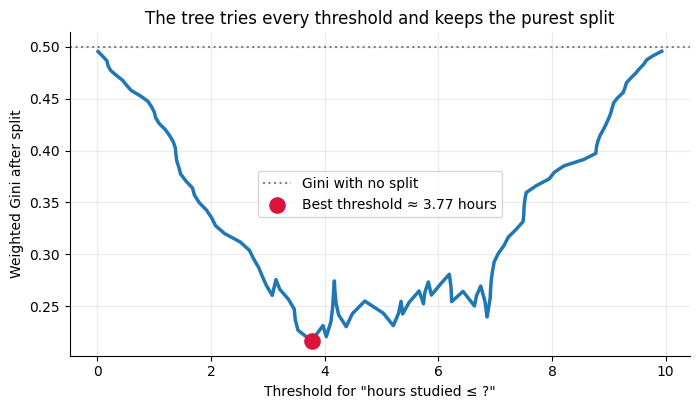

In [15]:
# ── Gini impurity by hand ───────────────────────────────────────────────────
def gini(labels):
    """Gini impurity of a group of 0/1 labels."""
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)                       # fraction of class 1
    return 1 - p ** 2 - (1 - p) ** 2

def split_score(x, y, threshold):
    """Weighted Gini impurity after splitting on "x <= threshold"."""
    left, right = y[x <= threshold], y[x > threshold]
    return (len(left) * gini(left) + len(right) * gini(right)) / len(y)

hours = X_pass.ravel()
values = np.sort(np.unique(hours))
candidate_thresholds = (values[:-1] + values[1:]) / 2      # midpoints between neighboring values
scores = np.array([split_score(hours, y_pass, t) for t in candidate_thresholds])
best_t = candidate_thresholds[np.argmin(scores)]

# A depth-1 tree (a "stump") asks exactly one question
stump = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_pass, y_pass)

print(f"Gini before splitting:           {gini(y_pass):.3f}")
print(f"Best split found by hand:        hours <= {best_t:.3f}   (weighted Gini = {scores.min():.3f})")
print(f"Split chosen by scikit-learn:    hours <= {stump.tree_.threshold[0]:.3f}")
left, right = y_pass[hours <= best_t], y_pass[hours > best_t]
print(f"\n  Left  group (≤ {best_t:.2f} h): {len(left):>3} students, {left.mean():.0%} passed  -> Gini {gini(left):.3f}")
print(f"  Right group (> {best_t:.2f} h): {len(right):>3} students, {right.mean():.0%} passed  -> Gini {gini(right):.3f}")

plt.figure(figsize=(8, 4.2))
plt.plot(candidate_thresholds, scores, lw=2.5)
plt.axhline(gini(y_pass), color='gray', ls=':', label='Gini with no split')
plt.scatter([best_t], [scores.min()], color='crimson', s=120, zorder=3, label=f'Best threshold ≈ {best_t:.2f} hours')
plt.xlabel('Threshold for "hours studied ≤ ?"'); plt.ylabel('Weighted Gini after split')
plt.title('The tree tries every threshold and keeps the purest split'); plt.legend()
plt.show()

Our hand calculation and scikit-learn agree. Then the tree simply **repeats the same search inside each child group**, splitting again and again:

```
1. Start with all training examples at the root
2. Try every feature and every threshold; keep the split with the lowest weighted impurity
3. Send the examples left or right according to that question
4. Repeat steps 2–3 on each child until a stopping rule is hit
   (max_depth reached, too few examples to split, or the group is already pure)
5. Each leaf predicts the majority class of its training examples
```

This is called **greedy** splitting: the tree always grabs the best split *right now*, without planning ahead. It's fast, but it means
the tree isn't guaranteed to find the best possible tree overall.

> **Gini vs. entropy:** scikit-learn can also measure impurity with **entropy**, $-\sum_k p_k \log_2 p_k$, the same quantity behind log loss.
> Set `criterion='entropy'` to use it. In practice the two almost always pick very similar splits.

---
## 4.3 Growing and Reading a Full Tree

Now a harder problem. In this course, students pass if they study enough **and** sleep enough, or if they study a huge amount.
That rule involves an **interaction** between features, which a single straight line can't express.

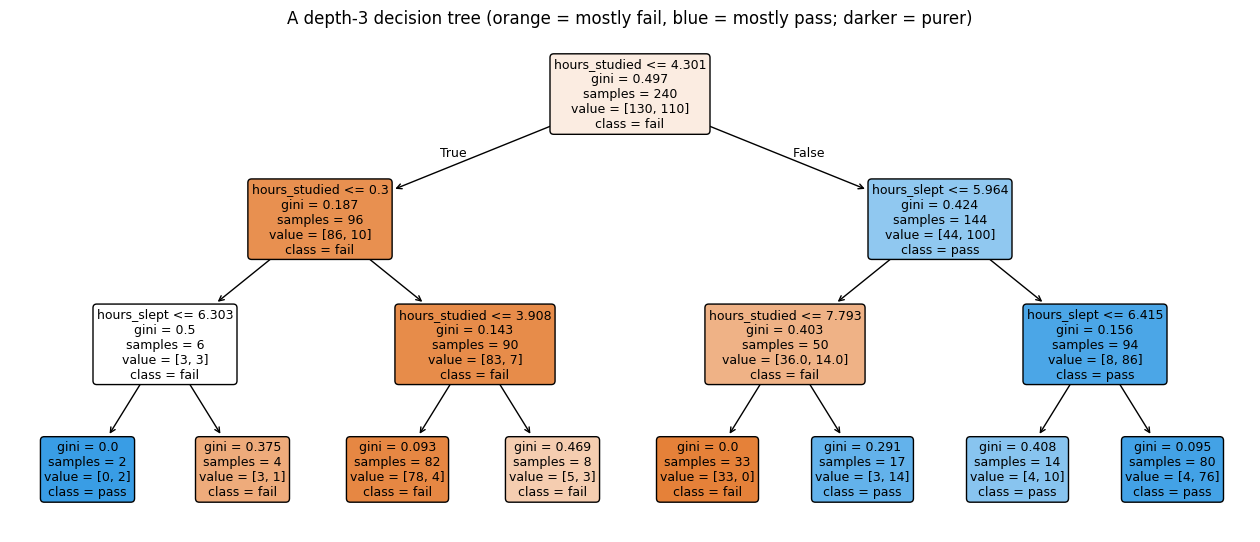

The same tree as text rules:

|--- hours_studied <= 4.30
|   |--- hours_studied <= 0.30
|   |   |--- hours_slept <= 6.30
|   |   |   |--- class: 1
|   |   |--- hours_slept >  6.30
|   |   |   |--- class: 0
|   |--- hours_studied >  0.30
|   |   |--- hours_studied <= 3.91
|   |   |   |--- class: 0
|   |   |--- hours_studied >  3.91
|   |   |   |--- class: 0
|--- hours_studied >  4.30
|   |--- hours_slept <= 5.96
|   |   |--- hours_studied <= 7.79
|   |   |   |--- class: 0
|   |   |--- hours_studied >  7.79
|   |   |   |--- class: 1
|   |--- hours_slept >  5.96
|   |   |--- hours_slept <= 6.42
|   |   |   |--- class: 1
|   |   |--- hours_slept >  6.42
|   |   |   |--- class: 1



In [16]:
# ── Helper: create data with an interaction between features ────────────────
def making_data_for_decision_tree():
    """
    Returns 400 students with two features and a pass (1) / fail (0) label:
      - hours studied per day (0 to 10)
      - hours slept per night (4 to 10)
    Hidden rule: PASS if (studied > 4 AND slept > 6) OR studied > 8.
    10% of labels are flipped at random to act as noise (real life is messy!).
    """
    rng = np.random.RandomState(0)
    n = 400
    studied = rng.uniform(0, 10, n)
    slept   = rng.uniform(4, 10, n)
    passed  = (((studied > 4) & (slept > 6)) | (studied > 8)).astype(int)
    flip = rng.rand(n) < 0.10
    passed[flip] = 1 - passed[flip]
    return np.column_stack([studied, slept]), passed

X_tree, y_tree = making_data_for_decision_tree()
tree_features = ['hours_studied', 'hours_slept']

# Split into train / validation / test (60 / 20 / 20)
Xt_train, Xt_temp, yt_train, yt_temp = train_test_split(X_tree, y_tree, test_size=0.4, random_state=42, stratify=y_tree)
Xt_val, Xt_test, yt_val, yt_test     = train_test_split(Xt_temp, yt_temp, test_size=0.5, random_state=42, stratify=yt_temp)

tree3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xt_train, yt_train)

plt.figure(figsize=(16, 6.5))
plot_tree(tree3, feature_names=tree_features, class_names=['fail', 'pass'],
          filled=True, rounded=True, impurity=True, fontsize=9)
plt.title('A depth-3 decision tree (orange = mostly fail, blue = mostly pass; darker = purer)')
plt.show()

print("The same tree as text rules:\n")
print(export_text(tree3, feature_names=tree_features))

**How to read each box:** the first line is the question (go **left if true**, right if false); `gini` is that node's impurity;
`samples` is how many training students reached it; `value` is the count of [fail, pass]; and `class` is the majority vote, which becomes
the prediction if this is a leaf.

The tree discovered thresholds close to the hidden rule (around 4 and 8 hours of studying, and 6 hours of sleep) **all on its own**, just by
searching for pure splits. Some of its later splits are less sensible, though: those are reacting to the noisy labels. That's the first hint of the main weakness of trees.

---
## 4.4 Trees Carve the Space into Rectangles

Each question splits on **one feature at a time**, so every split is a vertical or horizontal line. Stack several and the tree divides the
feature space into **rectangles**, each with one prediction. Compare that to logistic regression's single straight line on the same data:

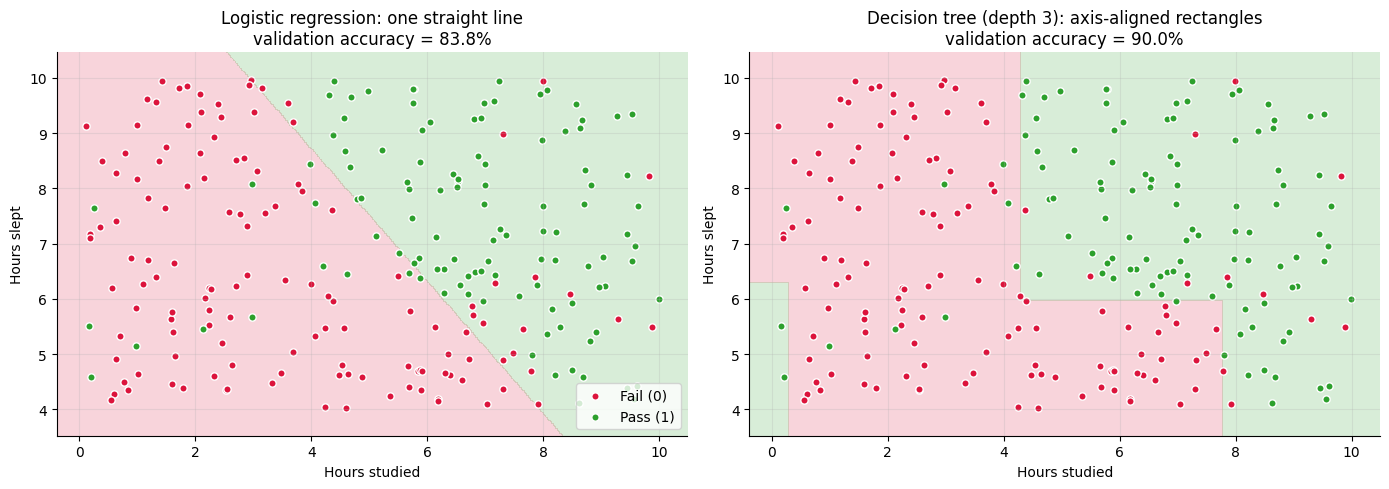

In [17]:
# ── Logistic regression vs. decision tree on data with an interaction ───────
logit_tree_data = LogisticRegression().fit(Xt_train, yt_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_decision_boundary(axes[0], logit_tree_data, Xt_train, yt_train,
                       f'Logistic regression: one straight line\nvalidation accuracy = {logit_tree_data.score(Xt_val, yt_val):.1%}',
                       ylabel='Hours slept')
plot_decision_boundary(axes[1], tree3, Xt_train, yt_train,
                       f'Decision tree (depth 3): axis-aligned rectangles\nvalidation accuracy = {tree3.score(Xt_val, yt_val):.1%}',
                       ylabel='Hours slept')
axes[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

The real pattern is shaped like a staircase, and the tree's rectangles match it naturally. Logistic regression can only draw one diagonal
line through it, so it gets more students wrong. **Neither model is "better" in general** — on the earlier 2-feature dataset, where the
true boundary really was a straight diagonal line, the tree would have had to approximate that line with a jagged staircase of tiny rectangles.

---
## 4.5 Depth, Overfitting, and How to Stop It

Left unchecked, a tree keeps splitting until **every leaf is perfectly pure**, which means it memorizes the training data, noise and all.
This is the classic **high-variance** model from the bias–variance discussion:

* **Shallow tree** (small `max_depth`): too few questions → **underfits** (high bias).
* **Very deep tree**: a question for every quirk → **overfits** (high variance).

Let's sweep `max_depth`, choose the best depth with the **validation set**, and check the final choice once on the **test set**.

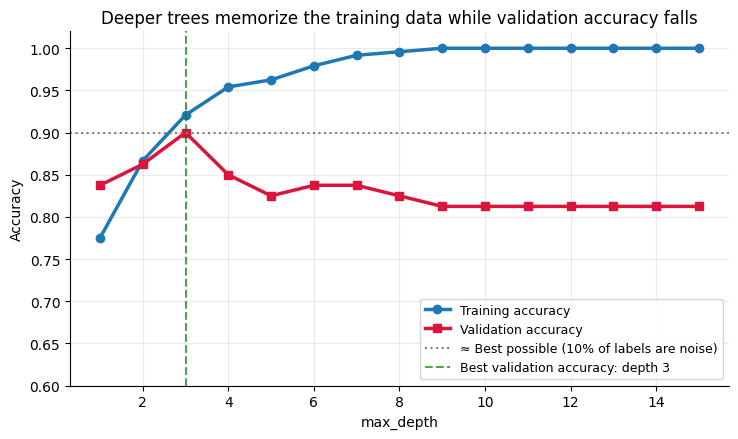

Unlimited depth:  grew to depth 9 with 34 leaves
                  train accuracy 100.0%, validation accuracy 81.2%   <- memorized
Depth 3 (chosen):  8 leaves, train 92.1%, validation 90.0%
Final test accuracy of the depth-3 tree: 90.0%   <- evaluated once, at the very end


In [18]:
# ── Training vs. validation accuracy as the tree grows deeper ───────────────
depths = range(1, 16)
train_acc, val_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xt_train, yt_train)
    train_acc.append(t.score(Xt_train, yt_train))
    val_acc.append(t.score(Xt_val, yt_val))

best_depth = list(depths)[int(np.argmax(val_acc))]
final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(Xt_train, yt_train)
full_tree  = DecisionTreeClassifier(random_state=42).fit(Xt_train, yt_train)       # no depth limit at all

plt.figure(figsize=(8.5, 4.6))
plt.plot(list(depths), train_acc, 'o-', lw=2.5, label='Training accuracy')
plt.plot(list(depths), val_acc,   's-', lw=2.5, color='crimson', label='Validation accuracy')
plt.axhline(0.90, color='gray', ls=':', label='≈ Best possible (10% of labels are noise)')
plt.axvline(best_depth, color='green', ls='--', alpha=0.7, label=f'Best validation accuracy: depth {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.ylim(0.6, 1.02)
plt.title('Deeper trees memorize the training data while validation accuracy falls'); plt.legend(fontsize=9)
plt.show()

print(f"Unlimited depth:  grew to depth {full_tree.get_depth()} with {full_tree.get_n_leaves()} leaves")
print(f"                  train accuracy {full_tree.score(Xt_train, yt_train):.1%}, validation accuracy {full_tree.score(Xt_val, yt_val):.1%}   <- memorized")
print(f"Depth {best_depth} (chosen):  {final_tree.get_n_leaves()} leaves, train {final_tree.score(Xt_train, yt_train):.1%}, validation {final_tree.score(Xt_val, yt_val):.1%}")
print(f"Final test accuracy of the depth-{best_depth} tree: {final_tree.score(Xt_test, yt_test):.1%}   <- evaluated once, at the very end")

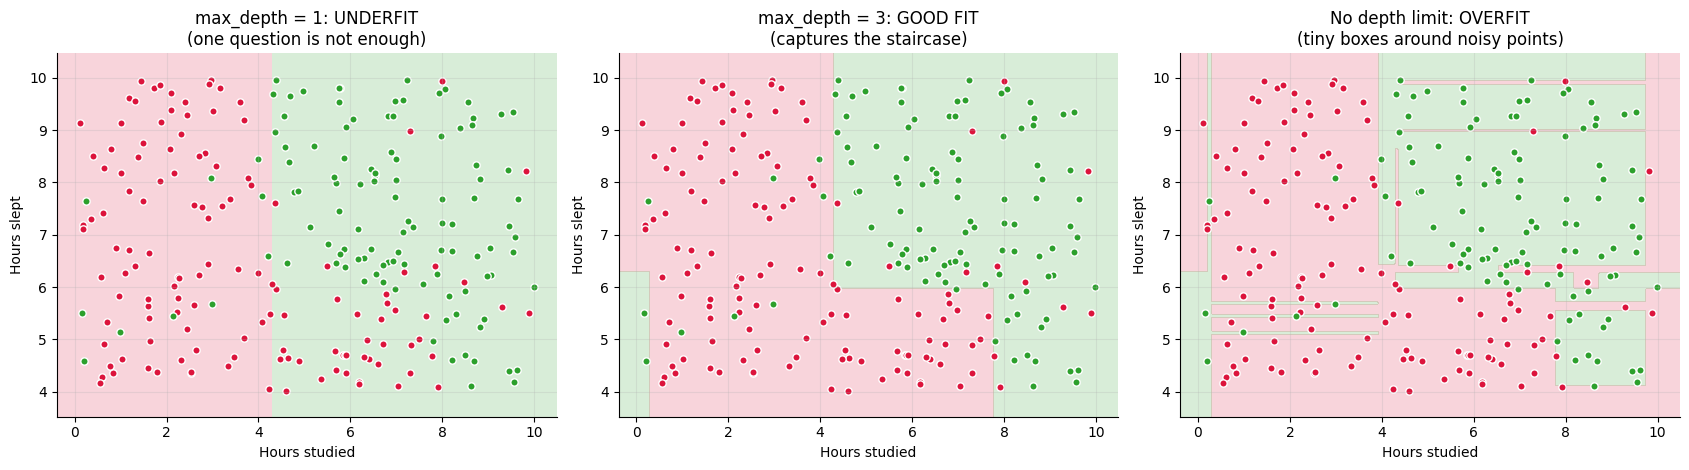

In [19]:
# ── See it: underfit, good fit, and overfit trees ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, model, title in zip(axes,
                            [DecisionTreeClassifier(max_depth=1, random_state=42).fit(Xt_train, yt_train), final_tree, full_tree],
                            ['max_depth = 1: UNDERFIT\n(one question is not enough)',
                             f'max_depth = {best_depth}: GOOD FIT\n(captures the staircase)',
                             f'No depth limit: OVERFIT\n(tiny boxes around noisy points)']):
    plot_decision_boundary(ax, model, Xt_train, yt_train, title, ylabel='Hours slept')
plt.tight_layout(); plt.show()

The unlimited tree on the right draws tiny boxes around individual noisy students. It scores perfectly on training data, but those boxes
are useless (or harmful) for new students.

**Ways to stop a tree from overfitting** (all are hyperparameters you tune on validation data):
* `max_depth` — limit how many questions in a row it can ask
* `min_samples_leaf` — require every leaf to contain at least this many training examples
* `min_samples_split` — don't split a node with fewer than this many examples
* Or average many trees together: that's a **Random Forest**, covered in a later chapter.

---
## 4.6 Regression Trees

Trees can predict numbers too. The only changes:
* Each **leaf predicts the average** target value of the training examples that land in it.
* Splits are chosen to minimize **MSE** inside the child groups, instead of Gini impurity.

Since each leaf outputs a single number, a regression tree's prediction is a **step function**. Let's try it on the curved sleep data from Part 2.

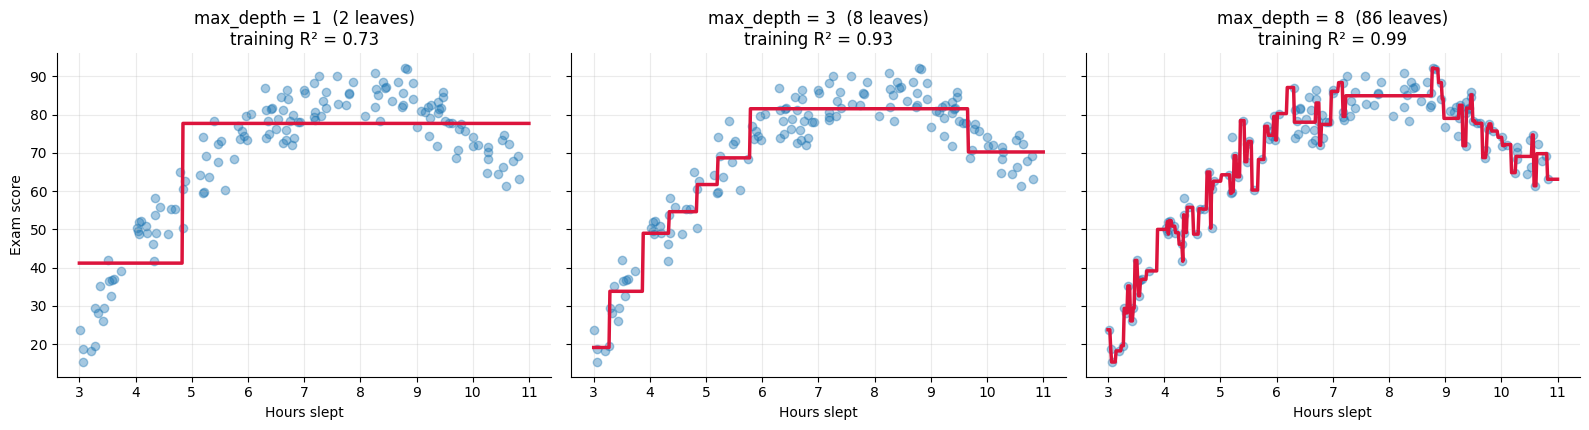

In [20]:
# ── Regression trees of different depths on the curved sleep data ──────────
grid = np.linspace(3, 11, 500).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, d in zip(axes, [1, 3, 8]):
    reg_tree = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_sleep, y_sleep)
    ax.scatter(X_sleep, y_sleep, alpha=0.4)
    ax.plot(grid, reg_tree.predict(grid), color='crimson', lw=2.5)
    ax.set_title(f'max_depth = {d}  ({reg_tree.get_n_leaves()} leaves)\ntraining R² = {r2_score(y_sleep, reg_tree.predict(X_sleep)):.2f}')
    ax.set_xlabel('Hours slept')
axes[0].set_ylabel('Exam score')
plt.tight_layout(); plt.show()

* **Depth 1:** two steps. Too crude to follow the curve.
* **Depth 3:** eight steps that trace the upside-down U nicely, with no feature engineering. Compare that to linear regression, which needed us to add $x^2$ by hand.
* **Depth 8:** jagged steps chasing individual points. A higher training $R^2$, but it's fitting noise.

> **One limitation to remember:** A tree can only predict values it saw in training, the averages in its leaves. It **cannot extrapolate**.
> Ask it about 14 hours of sleep and it will give the same answer as for 11 hours, while a linear model would continue its trend.

---
### Pros & Cons — Decision Trees

| Strengths | Weaknesses |
|-----------|------------|
| Easy to explain: it's a flowchart anyone can follow | **Overfits easily** if not limited |
| Captures non-linear patterns and interactions automatically | **Unstable**: small changes in the data can produce a very different tree |
| No feature scaling needed (splits only compare values to thresholds) | Boundaries are always axis-aligned "staircases" |
| Handles both regression and classification | Can't extrapolate beyond the training range |
| Gives a built-in **feature importance** score | A single tree is usually less accurate than an ensemble of trees |

**Best used when:** you need a model you can draw and explain, the pattern involves thresholds or interactions, or as the building block for Random Forests and boosting.

### Key Parameters — Decision Tree

| Parameter | What it does | Default | Effect of changing it |
|-----------|-------------|---------|----------------------|
| `max_depth` | Maximum number of questions on any path | `None` (no limit) | Higher = more complex, risk of overfitting; lower = simpler, may underfit. **The most important one to tune.** |
| `min_samples_leaf` | Minimum training examples required in each leaf | `1` | Higher = smoother, more stable predictions |
| `min_samples_split` | Minimum examples a node needs before it may split | `2` | Higher = fewer splits, simpler tree |
| `criterion` | How split quality is measured | `'gini'` (classifier), `'squared_error'` (regressor) | `'entropy'` for classification usually gives similar results |
| `max_features` | How many features to consider at each split | `None` (all) | Smaller values add randomness; mostly used inside Random Forests |
| `random_state` | Fixes randomness so you get the same tree each run | `None` | Any integer works — just keep it consistent |

> **Rule of thumb:** Never ship an unlimited tree. Start with `max_depth` between 3 and 6, then tune it on validation data.

### ✏️ Quick Check

1. A node contains 6 "pass" and 2 "fail" students. What is its Gini impurity?
2. Why don't decision trees need feature scaling, while logistic regression does?
3. An unlimited-depth tree gets 100% training accuracy and 71% validation accuracy. What's happening, and name two parameters that could fix it.

<details>
<summary><b>Click for answers</b></summary>

1. $p_{\text{pass}} = 0.75$, $p_{\text{fail}} = 0.25$, so Gini $= 1 - (0.75^2 + 0.25^2) = 1 - 0.625 =$ **0.375**.
2. A tree only asks "is this feature ≤ some threshold?" Rescaling a feature moves the threshold but produces the exact same split. Logistic regression multiplies features by weights, and its regularization penalty treats all weights equally, so feature scale matters.
3. **Overfitting (high variance)**: the tree memorized the training data. Limit it with `max_depth`, `min_samples_leaf`, or `min_samples_split` (or switch to a Random Forest).
</details>

---
# Part 5: Putting It Together

## 5.1 Regression Showdown: Linear Regression vs. Regression Tree

There's no model that wins on every problem. Which one does better depends on the **shape of the real pattern**. Let's compare them on two of our datasets:
* **The multi-feature student data** (Part 2.3), where the true pattern is linear.
* **The curved sleep data** (Part 2.5), where the true pattern is an upside-down U.

In [21]:
# ── Same models, two different datasets ─────────────────────────────────────
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_sleep, y_sleep, test_size=0.3, random_state=42)

datasets = {'Linear pattern (student features)': (Xm_train, Xm_test, ym_train, ym_test),
            'Curved pattern (hours slept)':      (Xs_train, Xs_test, ys_train, ys_test)}
models = {'Linear regression':               lambda: LinearRegression(),
          'Regression tree (max_depth = 4)': lambda: DecisionTreeRegressor(max_depth=4, random_state=42)}

rows = []
for data_name, (Xa, Xb, ya, yb) in datasets.items():
    for model_name, make_model in models.items():
        m = make_model().fit(Xa, ya)
        rows.append({'dataset': data_name, 'model': model_name,
                     'test RMSE': np.sqrt(mean_squared_error(yb, m.predict(Xb))),
                     'test R²': r2_score(yb, m.predict(Xb))})

results = pd.DataFrame(rows).pivot(index='model', columns='dataset', values='test RMSE').round(2)
print("Test RMSE (lower is better):\n")
print(results.to_string())

Test RMSE (lower is better):

dataset                          Curved pattern (hours slept)  Linear pattern (student features)
model                                                                                           
Linear regression                                       15.28                               5.26
Regression tree (max_depth = 4)                          4.92                               7.54


* On the **linear** data, linear regression wins. The tree has to approximate a smooth plane with a staircase of leaf averages, which adds error.
* On the **curved** data, the tree wins easily, because a plain straight line can't bend (unless we add $x^2$, as in Part 2.5).

**Lesson:** look at your data and your residuals, and always compare a few models on validation data before choosing one.

---
## 5.2 Classification Showdown on Real Data: Breast Cancer Diagnosis

Let's finish with a real dataset that ships with scikit-learn: measurements of **569 breast tumor biopsies**, described by 30 features
computed from microscope images (radius, texture, smoothness, and so on). The goal is to predict whether a tumor is **malignant** (cancerous) or **benign**.

Here a **false negative** (calling a malignant tumor benign) is far worse than a false positive, so we care a lot about **recall** for the malignant class.

569 tumors, 30 features
Malignant: 212 (37%),  Benign: 357 (63%)

Model                      Accuracy  Precision   Recall
-------------------------------------------------------
Logistic regression           96.5%      98.0%    92.5%
Decision tree (depth 4)       89.5%      97.5%    73.6%


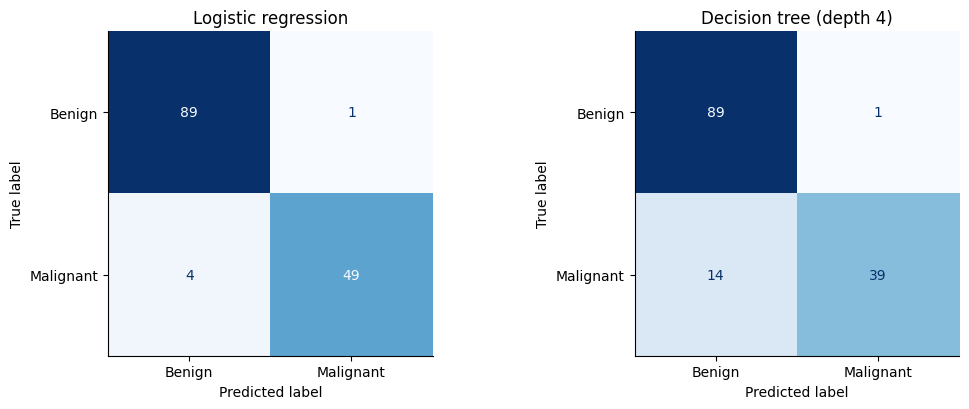

In [22]:
# ── Load the data ───────────────────────────────────────────────────────────
cancer = load_breast_cancer(as_frame=True)
X_bc = cancer.data
y_bc = 1 - cancer.target                  # sklearn codes malignant as 0; flip it so 1 = malignant (the class we want to catch)

print(f"{X_bc.shape[0]} tumors, {X_bc.shape[1]} features")
print(f"Malignant: {y_bc.sum()} ({y_bc.mean():.0%}),  Benign: {(1 - y_bc).sum()} ({1 - y_bc.mean():.0%})\n")

Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_bc, y_bc, test_size=0.25, random_state=42, stratify=y_bc)

# Logistic regression needs scaled features; the tree does not
bc_models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Decision tree (depth 4)': DecisionTreeClassifier(max_depth=4, random_state=42),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
print(f"{'Model':<25} {'Accuracy':>9} {'Precision':>10} {'Recall':>8}")
print("-" * 55)
for ax, (name, model) in zip(axes, bc_models.items()):
    model.fit(Xb_train, yb_train)
    pred = model.predict(Xb_test)
    print(f"{name:<25} {accuracy_score(yb_test, pred):>9.1%} {precision_score(yb_test, pred):>10.1%} {recall_score(yb_test, pred):>8.1%}")
    ConfusionMatrixDisplay(confusion_matrix(yb_test, pred), display_labels=['Benign', 'Malignant']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()

Logistic regression comes out ahead here. Many of these tumor measurements change smoothly and together, which suits a weighted sum,
while a single depth-4 tree can only use a handful of thresholds. (In a later chapter, a **Random Forest** of hundreds of trees closes this gap.)

### What did each model learn?

Both models can tell us which features they relied on, but in different ways:
* **Logistic regression:** the standardized **coefficients**. Sign shows direction (positive = pushes toward malignant); size shows strength.
* **Decision tree:** **feature importance**, the total impurity reduction a feature's splits produced, normalized to add up to 1.
  It shows *how much* a feature was used, not in which direction.

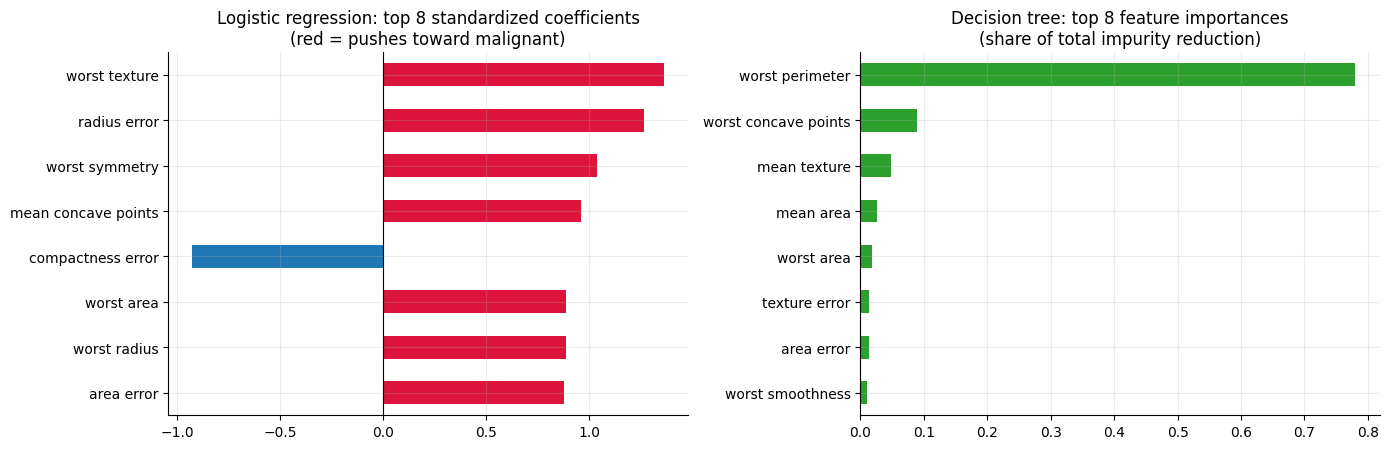

The tree used only 8 of the 30 features; logistic regression gives every feature a nonzero weight.


In [23]:
# ── Compare what each model relied on ───────────────────────────────────────
log_coefs = pd.Series(bc_models['Logistic regression'][-1].coef_[0], index=X_bc.columns)
tree_imp  = pd.Series(bc_models['Decision tree (depth 4)'].feature_importances_, index=X_bc.columns)

top_log  = log_coefs.reindex(log_coefs.abs().sort_values().index)[-8:]
top_tree = tree_imp.sort_values()[-8:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
top_log.plot.barh(ax=axes[0], color=['crimson' if c > 0 else 'tab:blue' for c in top_log])
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Logistic regression: top 8 standardized coefficients\n(red = pushes toward malignant)')
top_tree.plot.barh(ax=axes[1], color='tab:green')
axes[1].set_title('Decision tree: top 8 feature importances\n(share of total impurity reduction)')
plt.tight_layout(); plt.show()

print(f"The tree used only {(tree_imp > 0).sum()} of the 30 features; logistic regression gives every feature a nonzero weight.")

The two models tell somewhat different stories. The tree leans almost entirely on a **single size measurement** (`worst perimeter`), while logistic
regression spreads its weight across texture, size, concavity, and symmetry features. That isn't a contradiction. Radius, perimeter, and area all
measure tumor size and are strongly **correlated**, so a tree can pick any one of them and ignore the rest, while logistic regression can split the
credit among them in ways that are hard to interpret. Treat coefficients and importance scores as **clues about what a model used**, not proof of
what causes the outcome.

---
### Quick Guide: Which Model Should I Use?

| Situation | Good first choice |
|---|---|
| Predict a number, relationship looks roughly linear | **Linear Regression** |
| Predict a category, need probabilities or an explainable model | **Logistic Regression** |
| Pattern involves thresholds, interactions, or curves; want a flowchart you can show people | **Decision Tree** |
| Need the best possible accuracy | Try a tree ensemble (**Random Forest**, **XGBoost**) — covered later |
| Not sure? | Fit a simple linear/logistic baseline first, then see if a tree beats it on **validation data** |

---
# Chapter Summary

Well done making it through the chapter! Here is a full recap:

---

### Linear Regression
* Predicts a number as a weighted sum: $\hat{y} = w_1x_1 + \dots + w_px_p + b$.
* Trained by **least squares** (minimizing MSE), solved exactly by the normal equation or approximately by gradient descent.
* Coefficient $w_j$ = change in prediction per unit of $x_j$, **holding the other features fixed**. Standardize features to compare coefficients.
* Evaluate with **MAE**, **RMSE**, and **$R^2$** (fraction of variation explained) on test data, and check the residuals for patterns.
* Curved patterns need engineered features like $x^2$; "linear" means linear in the parameters.

### Logistic Regression
* A **classification** model: weighted sum $z$ → **sigmoid** $\sigma(z) = \frac{1}{1+e^{-z}}$ → probability → **threshold** → class.
* Trained by minimizing **log loss** with an iterative optimizer; the gradient has the same form as linear regression's.
* $e^{w}$ is the **odds ratio**: how much one extra unit of $x$ multiplies the odds of class 1.
* Its **decision boundary is a straight line** (linear classifier).
* Lower threshold → higher recall, lower precision; raise it for the opposite. sklearn regularizes by default (`C=1.0`).

### Decision Trees
* Predict by asking a sequence of **yes/no questions**; each leaf holds a prediction (majority class, or average value for regression).
* Splits are chosen greedily to minimize **Gini impurity** $1 - \sum_k p_k^2$ (or MSE for regression).
* Boundaries are **axis-aligned rectangles**; trees capture interactions and non-linear patterns with no scaling or feature engineering.
* Unlimited trees **overfit**: limit `max_depth` / `min_samples_leaf` and choose them on validation data.
* Regression trees produce **step functions** and cannot extrapolate.

| | Linear Regression | Logistic Regression | Decision Tree |
|---|---|---|---|
| **Task** | Regression | Classification | Both |
| **Shape of the fit** | Line / plane | Linear boundary + S-curve probability | Rectangles / steps |
| **Needs scaling?** | Only to compare coefficients | Yes (recommended) | No |
| **Main risk** | Underfitting non-linear patterns | Underfitting non-linear boundaries | Overfitting |
| **Interpretation** | Coefficients | Odds ratios | The flowchart + feature importance |

---

### Quick-Reference Code

```python
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score

# --- Linear regression ---
lin = LinearRegression().fit(X_train, y_train)
lin.coef_, lin.intercept_                              # learned weights and intercept
r2_score(y_test, lin.predict(X_test))

# --- Logistic regression (scale first!) ---
logit = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(X_train, y_train)
probs = logit.predict_proba(X_test)[:, 1]              # probability of class 1
preds = (probs >= 0.5).astype(int)                     # choose your own threshold
recall_score(y_test, preds)

# --- Decision tree ---
tree = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
plot_tree(tree, feature_names=feature_names, filled=True)
tree.feature_importances_

# --- Choose a hyperparameter on validation data, then test ONCE ---
best = max(range(1, 15), key=lambda d: DecisionTreeClassifier(max_depth=d).fit(X_train, y_train).score(X_val, y_val))
```

---

### ✏️ Check Your Understanding

1. You need to predict next month's electricity bill (in dollars) for each household. Which model(s) from this chapter could you use?
2. Your logistic regression's predicted probabilities are all between 0 and 1, but your colleague's "classifier" (a linear regression on 0/1 labels) predicts 1.4 for some cases. What's wrong with the colleague's approach?
3. Linear regression gives a coefficient of `−0.02` on `distance_to_campus_in_meters` and `+3.1` on `has_parking`. Can you conclude parking matters more than distance? Why or why not?
4. A decision tree's very first split is `income <= 52,000`. What does that tell you about how the tree chose it?
5. Your data has a clear threshold effect: customers who wait more than 10 minutes almost always leave a bad review. Which model would capture this most naturally?
6. Logistic regression and a decision tree both get 92% test accuracy on your problem. Name one reason you might pick each one.

<details>
<summary><b>Click for answers</b></summary>

1. **Linear regression** or a **regression tree** (the target is a number). Logistic regression is for categories.
2. Linear regression isn't bounded, so it can output impossible "probabilities" above 1 or below 0, and it's pulled around by points far from the boundary. Logistic regression's sigmoid keeps outputs between 0 and 1 and is trained with log loss, which suits classification.
3. **No.** The coefficients are in different units. Distance is measured in meters, so −0.02 per meter is −20 per kilometer. Standardize the features first, then compare.
4. Of every feature and every threshold it tried, splitting on income at 52,000 produced the **largest drop in impurity**: it separated the classes more cleanly than any other single question.
5. A **decision tree**: a split like `wait_minutes <= 10` captures a threshold effect directly, while a linear model would spread the effect smoothly across all wait times.
6. **Logistic regression:** well-calibrated probabilities, stable coefficients, odds-ratio interpretation, extrapolates smoothly. **Decision tree:** a flowchart non-experts can follow, no scaling needed, captures interactions automatically.
</details>

---

> **The Big Takeaway:** Linear regression, logistic regression, and decision trees all follow the same recipe: a model that turns features into a prediction,
> a loss that measures how wrong it is, and a training procedure that lowers that loss. Linear models draw **straight lines** and are easy to interpret;
> trees ask **yes/no questions** and capture non-linear patterns but overfit if left unchecked. Compare them on **validation data**, and judge the final choice on **unseen test data**.